# Proof validity · Poster figures

Run all cells from the Notebooks directory with the project kernel. The figures read saved predictions on CPU. Notebook 06 generates the score table from the selected theorem-and-proof models. Each figure is exported as a vector PDF and a 300 dpi PNG in `Results/poster_figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score

results = Path("../Results")
out = results / "poster_figures"
out.mkdir(exist_ok=True)
scores = pd.read_csv(results / "proof_scores.csv")
models = ["TF-IDF", "DistilBERT", "ModernBERT-base", "MathBERT", "DeBERTa-v3-base"]
names = ["TF-IDF + LR", "DistilBERT", "ModernBERT", "MathBERT", "DeBERTa-v3"]
test = scores.query("dataset == 'test'").copy()
challenge = scores.query("dataset == 'challenge'").copy()

for subset, expected_size in ((test, 89), (challenge, 42)):
    assert subset.groupby("model").size().to_dict() == {model: expected_size for model in models}
assert scores["invalid_score"].between(0, 1).all()
away_from_tie = scores["invalid_score"] != 0.5
assert ((scores.loc[away_from_tie, "invalid_score"] > 0.5) == (scores.loc[away_from_tie, "predicted"] == "Invalid")).all()

ink, muted, grid = "#172F3B", "#4D606B", "#DAE3E6"
teal, rust, purple = "#087F80", "#AE4824", "#665999"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12, "text.color": ink,
                     "axes.labelcolor": ink, "xtick.color": muted, "ytick.color": ink,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False, "axes.edgecolor": grid, "pdf.fonttype": 42})

def header(fig, title, subtitle):
    fig.text(0.035, 0.96, title, fontsize=20, weight="bold", va="top")
    fig.text(0.035, 0.875, subtitle, fontsize=12, color=muted, va="top")

def export(fig, name):
    for extension in ("pdf", "png"):
        fig.savefig(out / f"{name}.{extension}", dpi=300, facecolor="white", bbox_inches="tight", pad_inches=0.18)
    plt.show()
    plt.close(fig)

## 1. Where did each proof fall relative to the decision boundary?

Each point is one labeled test proof. Horizontal position is its model score for Invalid. Vertical jitter separates points and has no statistical meaning. TF-IDF uses the Invalid column of `predict_proba`; the BERTs use the Invalid column after softmax. These are uncalibrated scores. The native predictions determine all counts, including exact ties.

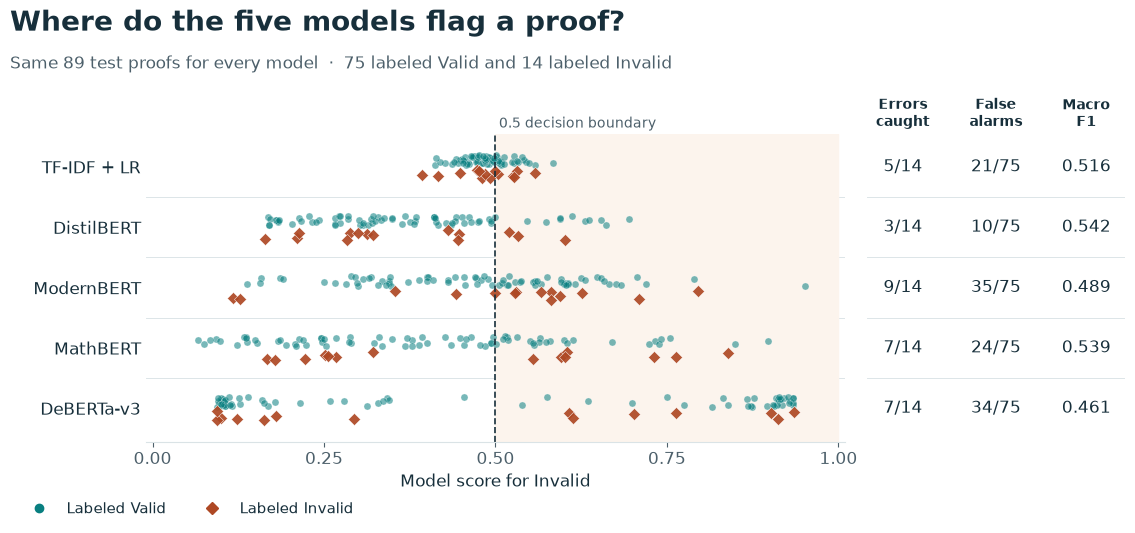

In [2]:
fig, (ax, table) = plt.subplots(1, 2, figsize=(11.8, 5.4), gridspec_kw={"width_ratios": [3.25, 1.2]})
fig.subplots_adjust(top=0.73, bottom=0.16, left=0.15, right=0.98, wspace=0.045)
header(fig, "Where do the five models flag a proof?",
       "Same 89 test proofs for every model  ·  75 labeled Valid and 14 labeled Invalid")
ax.axvspan(0.5, 1, color="#FCF4ED")
ax.axvline(0.5, linestyle="--", color=ink, lw=1.2)
ax.text(0.505, 1.02, "0.5 decision boundary", transform=ax.get_xaxis_transform(), color=muted, fontsize=10)
rng = np.random.default_rng(42)
for i, model in enumerate(models):
    data = test[test.model == model].sort_values("clean_row_index")
    for label, offset, color, shape in [("Valid", -0.11, teal, "o"), ("Invalid", 0.13, rust, "D")]:
        part = data[data.actual == label]
        y = i + offset + rng.uniform(-0.085, 0.085, len(part))
        ax.scatter(part.invalid_score, y, s=26 if label == "Valid" else 38, c=color, marker=shape,
                   alpha=0.55 if label == "Valid" else 0.92, linewidths=0.35, edgecolors="white")
    tn, fp, fn, tp = confusion_matrix(data.actual, data.predicted, labels=["Valid", "Invalid"]).ravel()
    for x, value in zip([0.14, 0.50, 0.85], [f"{tp}/14", f"{fp}/75", f"{f1_score(data.actual, data.predicted, average='macro'):.3f}"]):
        table.text(x, i, value, ha="center", va="center", fontsize=12)
for panel in (ax, table):
    panel.set_ylim(4.55, -0.55)
    for y in np.arange(0.5, 4, 1):
        panel.axhline(y, color=grid, lw=0.65, zorder=0)
ax.set(xlim=(-0.01, 1.01), yticks=range(5), yticklabels=names, xlabel="Model score for Invalid")
ax.tick_params(axis="y", length=0)
ax.set_xticks([0, .25, .5, .75, 1])
table.set_xlim(0, 1)
table.set_axis_off()
for x, title in zip([0.14, 0.50, 0.85], ["Errors\ncaught", "False\nalarms", "Macro\nF1"]):
    table.text(x, 1.01, title, transform=table.transAxes, ha="center", va="bottom", fontsize=10, weight="bold")
handles = [Line2D([], [], color=c, marker=m, linestyle="none", label=s) for c, m, s in
           [(teal, "o", "Labeled Valid"), (rust, "D", "Labeled Invalid")]]
fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.035, -0.005), ncol=2, frameon=False, fontsize=11)
export(fig, "01_test_scores")

## 2. What changed when review reasons were available during training?

The four BERTs always receive just the theorem and proof at test time. Lines connect the two fine-tuned versions of a model. The TF-IDF reason experiment used a reason at test time too, so this comparison uses the BERT experiments. The triangles show the separate zero-update baseline for Macro F1.

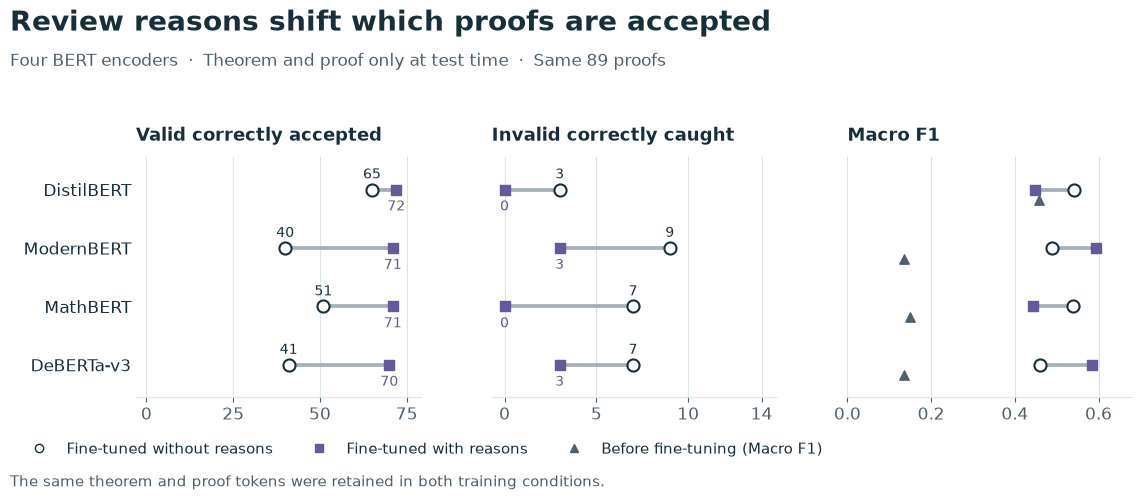

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5.1), sharey=True)
fig.subplots_adjust(top=0.67, bottom=0.20, left=0.14, right=0.97, wspace=0.25)
header(fig, "Review reasons shift which proofs are accepted",
       "Four BERT encoders  ·  Theorem and proof only at test time  ·  Same 89 proofs")
for i, model in enumerate(models[1:]):
    saved = pd.read_csv(results / model / "predictions.csv").query("split == 'test'")
    endpoints = []
    for variant in ("without_review_reason", "with_training_review_reason"):
        data = saved[saved.training_input == variant]
        tn, fp, fn, tp = confusion_matrix(data.actual, data.predicted, labels=["Valid", "Invalid"]).ravel()
        endpoints.append((tn, tp, f1_score(data.actual, data.predicted, average="macro")))
    untrained = pd.read_csv(results / model / "without_training" / "metrics.csv").query("Split == 'test'").iloc[0]
    for j, ax in enumerate(axes):
        first, second = endpoints[0][j], endpoints[1][j]
        ax.plot([first, second], [i, i], color="#A4B0B5", lw=2.7, zorder=1)
        ax.scatter(first, i, color="white", edgecolor=ink, lw=1.5, s=76, zorder=3)
        ax.scatter(second, i, color=purple, marker="s", s=62, zorder=4)
        if j < 2:
            ax.annotate(str(first), (first, i), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=10)
            ax.annotate(str(second), (second, i), xytext=(0, -15), textcoords="offset points", ha="center", fontsize=10, color=purple)
        else:
            ax.scatter(untrained["Macro F1"], i + .18, marker="^", s=45, color=muted, zorder=3)
for ax, title, limit, ticks in zip(axes, ["Valid correctly accepted", "Invalid correctly caught", "Macro F1"],
                                  [(-3, 79), (-0.7, 14.8), (0, .68)], [[0, 25, 50, 75], [0, 5, 10, 14], [0, .2, .4, .6]]):
    ax.set(xlim=limit, xticks=ticks, ylim=(3.55, -0.55), yticks=range(4), yticklabels=names[1:])
    ax.set_title(title, loc="left", fontsize=13, weight="bold", pad=12)
    ax.grid(axis="x", color=grid, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], marker=marker, markerfacecolor=color, markeredgecolor=edge, ls="none", label=label)
                    for marker, color, edge, label in [("o","white",ink,"Fine-tuned without reasons"),
                    ("s",purple,purple,"Fine-tuned with reasons"),("^",muted,muted,"Before fine-tuning (Macro F1)")]],
           loc="lower left", bbox_to_anchor=(.035, .055), ncol=3, frameon=False, fontsize=11)
fig.text(.035, .025, "The same theorem and proof tokens were retained in both training conditions.", fontsize=11, color=muted)
export(fig, "02_review_reasons")

## 3. Did a flawed edit move the score enough to change the label?

For each original and its primary edit, subtract the original Invalid score from the edited score. A positive change moves toward Invalid. A dot marks a proof that actually crossed to Invalid. Some theorems have two proof versions; the row index identifies the version. These 16 originals were selected because all five models accepted them.

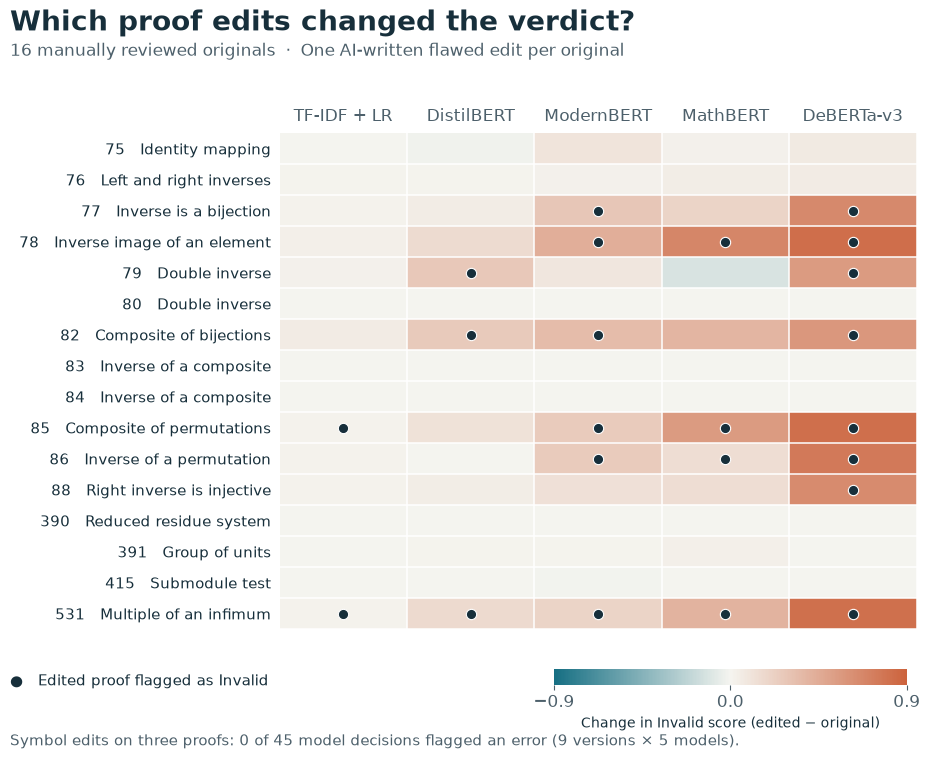

In [4]:
original = challenge[challenge.variant_id.str.endswith("-original")].pivot(index="clean_row_index", columns="model", values="invalid_score")
edited = challenge[challenge.variant_id.str.endswith("-primary")]
delta = (edited.pivot(index="clean_row_index", columns="model", values="invalid_score") - original)[models].sort_index()
caught = edited.pivot(index="clean_row_index", columns="model", values="predicted").loc[delta.index, models].eq("Invalid")
assert len(delta) == 16 and challenge[challenge.variant_id.str.endswith("-original")].predicted.eq("Valid").all()
titles = {75:"Identity mapping", 76:"Left and right inverses", 77:"Inverse is a bijection",
          78:"Inverse image of an element", 79:"Double inverse", 80:"Double inverse", 82:"Composite of bijections",
          83:"Inverse of a composite", 84:"Inverse of a composite", 85:"Composite of permutations",
          86:"Inverse of a permutation", 88:"Right inverse is injective", 390:"Reduced residue system",
          391:"Group of units", 415:"Submodule test", 531:"Multiple of an infimum"}
fig, ax = plt.subplots(figsize=(9.8, 8.0))
fig.subplots_adjust(top=.81, bottom=.19, left=.31, right=.96)
fig.text(.035, .965, "Which proof edits changed the verdict?", fontsize=20, weight="bold", va="top")
fig.text(.035, .907, "16 manually reviewed originals  ·  One AI-written flawed edit per original", fontsize=12, color=muted)
cmap = LinearSegmentedColormap.from_list("score_change", ["#166F83", "#F5F5F0", "#CC633D"])
bound = max(0.1, np.ceil(delta.abs().to_numpy().max()*10)/10)
im = ax.imshow(delta, cmap=cmap, norm=TwoSlopeNorm(0, -bound, bound), aspect="auto")
ys, xs = np.where(caught)
ax.scatter(xs, ys, color=ink, edgecolors="white", linewidths=.8, s=55)
ax.set_xticks(range(5), labels=names)
ax.xaxis.tick_top()
ax.set_yticks(range(len(delta)), labels=[f"{i}   {titles[i]}" for i in delta.index], fontsize=10.5)
ax.tick_params(axis="both", length=0, pad=6)
ax.set_xticks(np.arange(.5, 5), minor=True)
ax.set_yticks(np.arange(.5, len(delta)), minor=True)
ax.grid(which="minor", color="white", linewidth=1.1)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.text(.035, .12, "●   Edited proof flagged as Invalid", fontsize=11)
cax = fig.add_axes([.59, .121, .36, .019])
bar = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[-bound, 0, bound])
bar.set_label("Change in Invalid score (edited − original)", fontsize=10)
bar.outline.set_visible(False)
symbols = ["84-primary","84-symbol-2","84-symbol-3","390-primary","390-symbol-2","390-symbol-3",
           "531-symbol-1","531-symbol-2","531-symbol-3"]
symbol_preds = challenge[challenge.variant_id.isin(symbols)]
assert len(symbol_preds) == 45
n_flagged = symbol_preds.predicted.eq("Invalid").sum()
fig.text(.035, .045, f"Symbol edits on three proofs: {n_flagged} of 45 model decisions flagged an error (9 versions × 5 models).",
         fontsize=11, color=muted)
export(fig, "03_proof_edits")